In [30]:
import pandas as pd

df = pd.read_csv("data.csv", encoding="ISO-8859-1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [31]:
print(df.shape)
print(df.columns.tolist())
df.info()

(225826, 8)
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225826 entries, 0 to 225825
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    225826 non-null  object 
 1   StockCode    225825 non-null  object 
 2   Description  224960 non-null  object 
 3   Quantity     225825 non-null  float64
 4   InvoiceDate  225825 non-null  object 
 5   UnitPrice    225825 non-null  float64
 6   CustomerID   161926 non-null  float64
 7   Country      225825 non-null  object 
dtypes: float64(3), object(5)
memory usage: 13.8+ MB


In [32]:
print("=== Missing values per column ===")
missing = df.isnull().sum()
print(missing)

print("\n=== Percentage missing per column ===")
print((missing / len(df) * 100).round(2))

print("\n=== Missing values by Country (relevant category) ===")
missing_by_country = df[df.isnull().any(axis=1)].groupby("Country").size().sort_values(ascending=False)
print(missing_by_country.head(10))

=== Missing values per column ===
InvoiceNo          0
StockCode          1
Description      866
Quantity           1
InvoiceDate        1
UnitPrice          1
CustomerID     63900
Country            1
dtype: int64

=== Percentage missing per column ===
InvoiceNo       0.00
StockCode       0.00
Description     0.38
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     28.30
Country         0.00
dtype: float64

=== Missing values by Country (relevant category) ===
Country
United Kingdom    63442
EIRE                240
Hong Kong           184
Israel               20
Unspecified          11
Bahrain               2
dtype: int64


In [33]:
print("=== Fully duplicate rows (every column identical) ===")
dup_rows = df.duplicated()
print(f"Number of duplicate rows: {dup_rows.sum()}")
print(df[dup_rows].head())

=== Fully duplicate rows (every column identical) ===
Number of duplicate rows: 1877
    InvoiceNo StockCode                        Description  Quantity  \
517    536409     21866        UNION JACK FLAG LUGGAGE TAG       1.0   
527    536409     22866      HAND WARMER SCOTTY DOG DESIGN       1.0   
537    536409     22900    SET 2 TEA TOWELS I LOVE LONDON        1.0   
539    536409     22111       SCOTTIE DOG HOT WATER BOTTLE       1.0   
555    536412     22327  ROUND SNACK BOXES SET OF 4 SKULLS       1.0   

         InvoiceDate  UnitPrice  CustomerID         Country  
517  12/1/2010 11:45       1.25     17908.0  United Kingdom  
527  12/1/2010 11:45       2.10     17908.0  United Kingdom  
537  12/1/2010 11:45       2.95     17908.0  United Kingdom  
539  12/1/2010 11:45       4.95     17908.0  United Kingdom  
555  12/1/2010 11:49       2.95     17920.0  United Kingdom  


In [34]:
print("=== Repeated InvoiceNo values ===")
invoice_counts = df["InvoiceNo"].value_counts()
repeated_invoices = invoice_counts[invoice_counts > 1]

print(f"Number of InvoiceNo values appearing more than once: {repeated_invoices.shape[0]}")
print(repeated_invoices.head(10))

print("\n=== Example: all line items for one repeated InvoiceNo ===")
example_invoice = repeated_invoices.index[0]
print(df[df["InvoiceNo"] == example_invoice])

=== Repeated InvoiceNo values ===
Number of InvoiceNo values appearing more than once: 8871
InvoiceNo
537434    675
538071    652
538349    620
537638    601
537237    597
536876    593
536592    592
537823    591
537240    568
537666    536
Name: count, dtype: int64

=== Example: all line items for one repeated InvoiceNo ===
      InvoiceNo StockCode                       Description  Quantity  \
13270    537434     20685             DOORMAT RED RETROSPOT       1.0   
13271    537434     20699         MOUSEY LONG LEGS SOFT TOY       1.0   
13272    537434     20713                    JUMBO BAG OWLS       1.0   
13273    537434     20719            WOODLAND CHARLOTTE BAG       3.0   
13274    537434     20725           LUNCH BAG RED RETROSPOT       4.0   
...         ...       ...                               ...       ...   
13940    537434     20652        BLUE POLKADOT LUGGAGE TAG        2.0   
13941    537434     20658         RED RETROSPOT LUGGAGE TAG       1.0   
13942    537434

In [35]:
print(f"Rows before cleaning: {df.shape[0]}")
df = df.dropna(subset=["Quantity", "UnitPrice"])
df = df.drop_duplicates()
df_valid = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
print(f"Rows after cleaning: {df_valid.shape[0]}")

Rows before cleaning: 225826
Rows after cleaning: 218509


In [36]:
df_valid["Revenue"] = df_valid["Quantity"] * df_valid["UnitPrice"]
print("=== Revenue column added ===")
print(df_valid[["InvoiceNo", "Quantity", "UnitPrice", "Revenue"]].head())

=== Revenue column added ===
  InvoiceNo  Quantity  UnitPrice  Revenue
0    536365       6.0       2.55    15.30
1    536365       6.0       3.39    20.34
2    536365       8.0       2.75    22.00
3    536365       6.0       3.39    20.34
4    536365       6.0       3.39    20.34


In [37]:
order_values = df_valid.groupby("InvoiceNo")["Revenue"].sum()
max_order_value = order_values.max()
max_order_id = order_values.idxmax()
print(f"Highest order value: {max_order_value:.2f}")
print(f"InvoiceNo with the highest order value: {max_order_id}")
print("\n=== Line items for the highest-value order ===")
print(df_valid[df_valid["InvoiceNo"] == max_order_id])

Highest order value: 77183.60
InvoiceNo with the highest order value: 541431

=== Line items for the highest-value order ===
      InvoiceNo StockCode                     Description  Quantity  \
61619    541431     23166  MEDIUM CERAMIC TOP STORAGE JAR   74215.0   

           InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
61619  1/18/2011 10:01       1.04     12346.0  United Kingdom  77183.6  


In [38]:
max_unit_price = df_valid["UnitPrice"].max()
print(f"Highest unit price: {max_unit_price:.2f}")

print("\n=== Product(s) with the highest unit price ===")
print(df_valid[df_valid["UnitPrice"] == max_unit_price][["StockCode", "Description", "UnitPrice"]])

Highest unit price: 13541.33

=== Product(s) with the highest unit price ===
       StockCode Description  UnitPrice
15017  AMAZONFEE  AMAZON FEE   13541.33


In [39]:
revenue_by_country = (
    df_valid.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("=== Total revenue by country ===")
print(revenue_by_country)

print("\n=== Top 5 countries by revenue ===")
print(revenue_by_country.head(5))

=== Total revenue by country ===
                 Country      Revenue
0         United Kingdom  3747296.631
1            Netherlands   119340.660
2                Germany   102574.120
3                   EIRE    98282.260
4                 France    83275.860
5              Australia    56312.480
6                  Spain    25985.770
7            Switzerland    22568.010
8                  Japan    21434.730
9               Portugal    16655.560
10                Sweden    16483.280
11               Belgium    15483.160
12             Singapore    10262.650
13               Finland     9612.720
14                Cyprus     8516.520
15             Hong Kong     8320.520
16       Channel Islands     7833.390
17               Denmark     7796.660
18                 Italy     6804.170
19                Norway     5683.330
20               Austria     4433.890
21                Poland     4036.420
22                Greece     3658.290
23               Iceland     2205.950
24               

In [40]:
print("=" * 50)
print("E-COMMERCE DATA ANALYSIS SUMMARY")
print("=" * 50)

print(f"\nTotal rows analyzed (after cleaning): {df_valid.shape[0]}")

print(f"\n1. Missing values found (original dataset):")
print(missing[missing > 0])

print(f"\n2. Fully duplicate rows found: {dup_rows.sum()}")

print(f"\n3. Repeated InvoiceNo values: {repeated_invoices.shape[0]}")

print(f"\n4. Highest order value: {max_order_value:.2f} (InvoiceNo: {max_order_id})")

print(f"\n5. Highest unit price: {max_unit_price:.2f}")

print(f"\n6. Revenue by country (top 5):")
print(revenue_by_country.head(5).to_string(index=False))

E-COMMERCE DATA ANALYSIS SUMMARY

Total rows analyzed (after cleaning): 218509

1. Missing values found (original dataset):
StockCode          1
Description      866
Quantity           1
InvoiceDate        1
UnitPrice          1
CustomerID     63900
Country            1
dtype: int64

2. Fully duplicate rows found: 1877

3. Repeated InvoiceNo values: 8871

4. Highest order value: 77183.60 (InvoiceNo: 541431)

5. Highest unit price: 13541.33

6. Revenue by country (top 5):
       Country     Revenue
United Kingdom 3747296.631
   Netherlands  119340.660
       Germany  102574.120
          EIRE   98282.260
        France   83275.860


<Figure size 1000x500 with 0 Axes>

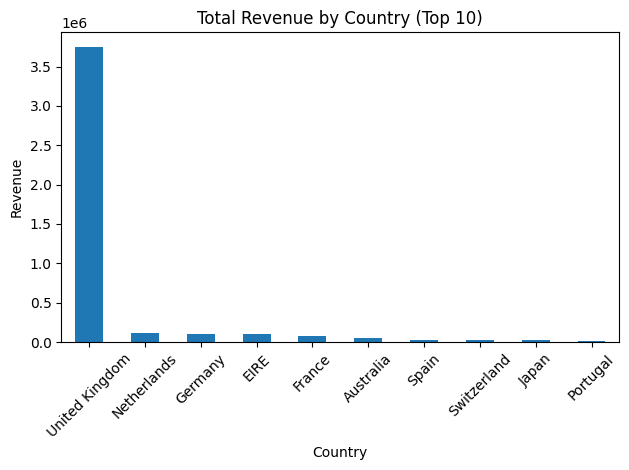

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
revenue_by_country.head(10).plot(kind="bar", x="Country", y="Revenue", legend=False)
plt.title("Total Revenue by Country (Top 10)")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("revenue_by_country.png")
plt.show()

## 6. Business Impact and Recommendations

### Comparison of Missing-Value Strategies

**Deleting (dropna):** Keeps only real data, but shrinks the dataset. Dropping rows
with missing `CustomerID` alone removes ~64,000 rows (~28%), which could skew
revenue and country totals if missingness isn't random.

**Filling with mean/median:** Keeps all rows, but fabricates values. Doesn't apply
to `CustomerID` (an ID can't be averaged). For `Quantity`/`UnitPrice`, median is
safer than mean, since retail data is often right-skewed and the mean would be
pulled up by bulk/high-value orders.

### Strategy by Column

| Column | Strategy | Why |
|---|---|---|
| `CustomerID` | Leave missing / label "Guest" | It's an ID, not a value — can't be averaged, and filling it fakes a customer |
| `Quantity` / `UnitPrice` | Drop (dropna) | Only ~1 row affected, and revenue can't be computed without both |
| `Description` | Fill with "Unknown" | Low impact on revenue/location analysis |

### Effect on Business Decisions

- Dropping `CustomerID` rows understates revenue in countries with more guest
  checkouts, making those regions look weaker than they are.
- Filling with the mean can overstate "typical" order value, leading to wrong
  conclusions about customer spend or regional performance.
- Median keeps revenue-by-country figures more reliable for budgeting decisions.

### Preventing Recurrence

- Require `CustomerID` or an explicit "Guest" flag at checkout.
- Validate `Quantity`/`UnitPrice` as numeric and positive at entry.
- Enforce column data types at the database/API level.
- Run automated data-quality checks before data reaches analytics.
- Use a dropdown for `Country`/`City` instead of free text.

### Common Causes and Fixes

| Cause | Fix |
|---|---|
| Typos/inconsistent casing in text fields | Standardize with `str.strip()`/`str.title()`; use dropdowns |
| Numbers stored as text | Validate and cast types at ingestion, not just analysis |
| Optional fields left blank | Make required, or auto-generate a default (e.g. guest ID) |
| Duplicate records from retries | Add a unique constraint/idempotency key |
| Returns mixed in with sales as negative quantity | Use a separate status column for returns |

In [ ]:
x